# 02a – A szöveges korpusz leíró jellemzői

Ez a notebook mutatja be, hány dokumentum érkezett forrásonként, évente, havonta, a hét napjai és a napszakok szerint. A napszak szerinti eloszlásból látszik, hogy a dokumentumok mekkora része jelenik meg a BÉT nyitvatartási idején kívül; ezeknek az eseményablaka a következő nyitással kezdődik (03. notebook).

**Bemenet:** a `korpusz.sqlite` adatbázis `dokumentum` táblája (a megjelenési idővel és szöveggel rendelkező dokumentumok).

| szakasz | tartalom |
|---|---|
| 0 | beállítások |
| 1 | dokumentumok forrásonként és évenként |
| 2 | időbeli eloszlás: hónap, a hét napja, napszak |

## 0. Beállítások

In [1]:
import os
import sqlite3
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PROJEKT = Path(r"C:\Users\User\Desktop\BGE Szakdolgozat")
DB = PROJEKT / "adat" / "korpusz.sqlite"
CACHE = Path(os.environ.get("CACHE_MAPPA", PROJEKT / "adat" / "cache"))
IZ = ZoneInfo("Europe/Budapest")


def db_olvas(sql):
    con = sqlite3.connect(f"file:{DB.as_posix()}?mode=ro", uri=True)
    try:
        return pd.read_sql(sql, con)
    finally:
        con.close()

## 1. Dokumentumok forrásonként és évenként

A megjelenési időt budapesti helyi időre váltom, mert a nyitvatartás helyi időben értendő.

In [2]:
dok = db_olvas("SELECT forras, megjelenes_utc FROM dokumentum WHERE megjelenes_utc IS NOT NULL AND szoveg IS NOT NULL")
ido = pd.to_datetime(dok.megjelenes_utc, utc=True).dt.tz_convert(IZ)
dok["ev"] = ido.dt.year
dok["honap"] = ido.dt.strftime("%Y-%m")
dok["het_napja"] = ido.dt.dayofweek
dok["ora"] = ido.dt.hour
print("Időszak:", ido.min(), "–", ido.max())
display(pd.crosstab(dok.forras, dok.ev, margins=True, margins_name="összesen"))

Időszak: 2024-01-02 06:00:00+01:00 – 2025-12-31 15:44:00+01:00


ev,2024,2025,összesen
forras,,,
bet,691,654,1345
portfolio,1419,947,2366
telex,142,177,319
összesen,2252,1778,4030


## 2. Időbeli eloszlás

Az óránkénti ábrán a zöld sáv a BÉT folyamatos kereskedési szakasza (09:00–17:00). A jobb oldali ábra és a hét napjai szerinti ábra a forrás összes dokumentumának százalékában mutatja az eloszlást, így a három forrás a méretétől függetlenül összevethető.

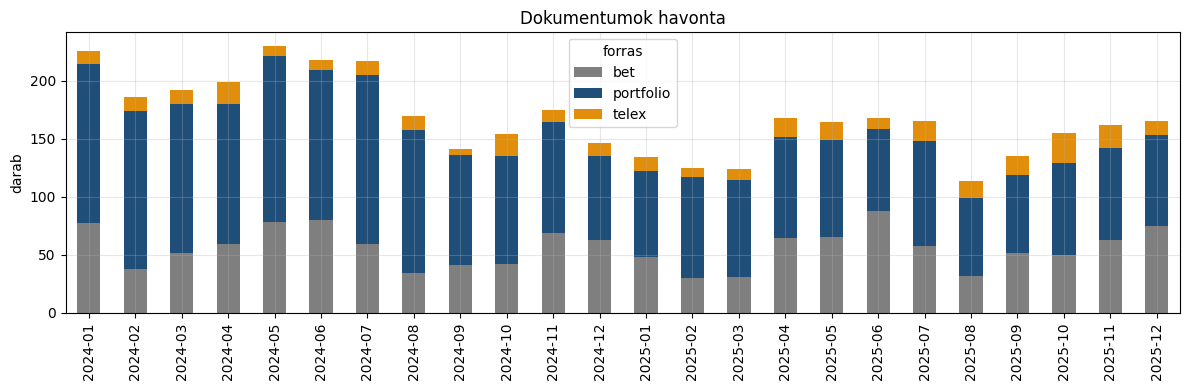

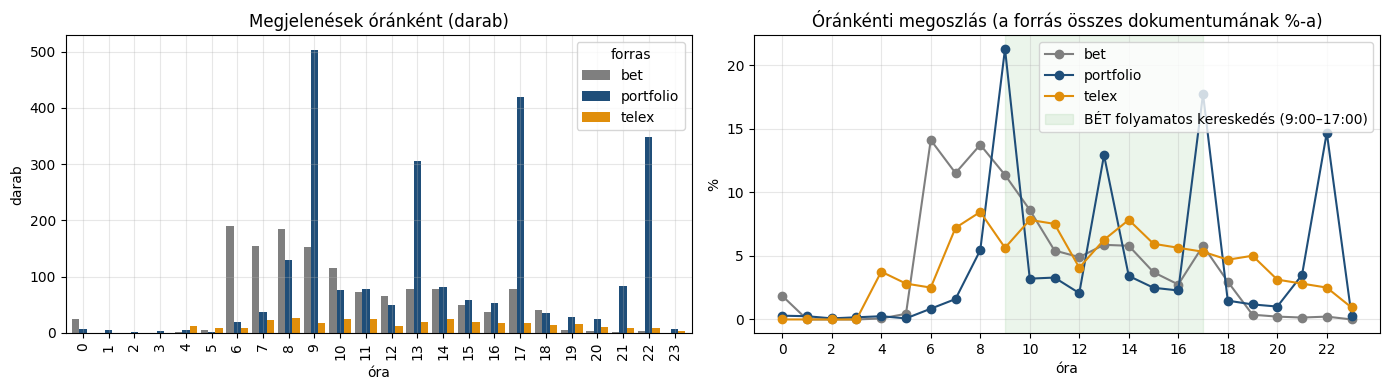

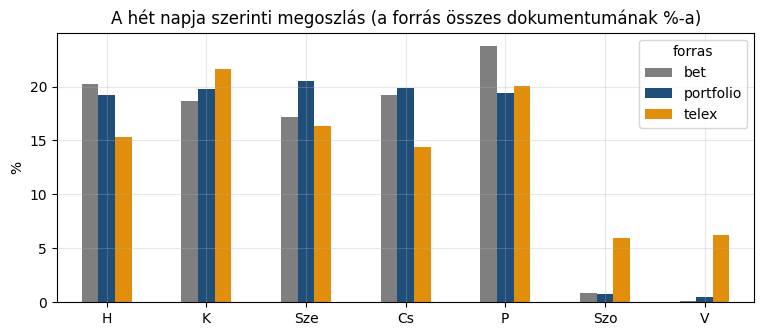

In [3]:
SZIN = {"bet": "#7f7f7f", "portfolio": "#1f4e79", "telex": "#e08e0b"}

havi = dok.groupby(["honap", "forras"]).size().unstack(fill_value=0)
havi.plot(kind="bar", stacked=True, figsize=(12, 4), color=[SZIN[f] for f in havi.columns])
plt.title("Dokumentumok havonta")
plt.xlabel("")
plt.ylabel("darab")
plt.tight_layout()
plt.show()

orak = dok.groupby(["ora", "forras"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
orak.plot(kind="bar", ax=ax[0], color=[SZIN[f] for f in orak.columns], width=0.85)
ax[0].set_title("Megjelenések óránként (darab)")
ax[0].set_xlabel("óra")
ax[0].set_ylabel("darab")
(100 * orak / orak.sum()).plot(ax=ax[1], marker="o", color=[SZIN[f] for f in orak.columns])
ax[1].axvspan(9, 17, color="green", alpha=0.08, label="BÉT folyamatos kereskedés (9:00–17:00)")
ax[1].set_title("Óránkénti megoszlás (a forrás összes dokumentumának %-a)")
ax[1].set_xlabel("óra")
ax[1].set_ylabel("%")
ax[1].set_xticks(range(0, 24, 2))
ax[1].legend()
plt.tight_layout()
plt.show()

napi = dok.groupby(["het_napja", "forras"]).size().unstack(fill_value=0)
napi.index = ["H", "K", "Sze", "Cs", "P", "Szo", "V"]
(100 * napi / napi.sum()).plot(kind="bar", figsize=(9, 3.5), color=[SZIN[f] for f in napi.columns])
plt.title("A hét napja szerinti megoszlás (a forrás összes dokumentumának %-a)")
plt.xlabel("")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

In [4]:
nyitvatartas = dok.het_napja.lt(5) & dok.ora.between(9, 16)
print("A hétköznap 9:00 és 17:00 között megjelent dokumentumok aránya forrásonként (%):")
print((100 * nyitvatartas.groupby(dok.forras).mean()).round(1).to_string())
print("Hétvégén megjelent dokumentumok aránya forrásonként (%):")
print((100 * dok.het_napja.ge(5).groupby(dok.forras).mean()).round(1).to_string())

A hétköznap 9:00 és 17:00 között megjelent dokumentumok aránya forrásonként (%):
forras
bet          48.4
portfolio    50.2
telex        45.8
Hétvégén megjelent dokumentumok aránya forrásonként (%):
forras
bet           0.9
portfolio     1.3
telex        12.2


**Eredmény.** A 4 030 dokumentumból 1 345 BÉT-közlemény, 2 366 Portfolio- és 319 Telex-cikk; 2024-ben 2 252, 2025-ben 1 778 dokumentum jelent meg. A dokumentumoknak csak kb. a fele jelenik meg hétköznap 9:00 és 17:00 között (BÉT 48,4%, Portfolio 50,2%, Telex 45,8%). A BÉT-közlemények óránkénti száma reggel 6 és 9 óra között, nyitás előtt a legnagyobb. A Portfolio eloszlásában négy kiugró óra van (9, 13, 17 és 22 óra), ezekben az órákban a cikkek egy része kötegben jelenik meg. Hétvégén szinte csak a Telex közöl (a cikkei 12,2%-a), a BÉT és a Portfolio dokumentumainak 1%-a körül. A cikkek megjelenések ideje is mutatja, hogy a portálok alapvetően különböznek egymástól.

In [15]:
df_t = db_olvas("""
    SELECT forras, ticker_gyenge, ticker_eros
    FROM dokumentum
    WHERE megjelenes_utc IS NOT NULL AND szoveg IS NOT NULL
""") 

FORRAS_NEV = {"bet": "BÉT", "portfolio": "Portfolio", "telex": "Telex"}
VALLALATOK = ["MOL", "MTELEKOM", "OTP", "RICHTER"]
OSZLOPOK = ["Csak erős", "Csak gyenge", "Vegyes"]


eros = df_t["ticker_eros"].fillna("").str.upper().str.findall(r"[A-ZÁÉÍÓÖŐÚÜŰ]+")
gyenge = df_t["ticker_gyenge"].fillna("").str.upper().str.findall(r"[A-ZÁÉÍÓÖŐÚÜŰ]+")

van_eros, van_gyenge = eros.str.len() > 0, gyenge.str.len() > 0
df_t["Kategória"] = np.select(
    [van_eros & van_gyenge, van_eros, van_gyenge],
    ["Vegyes", "Csak erős", "Csak gyenge"],
    default=None,
)

df_t["Forrás"] = df_t["forras"].map(FORRAS_NEV).fillna(df_t["forras"])
df_t["Vállalat"] = (eros + gyenge).apply(set)

bontott = df_t.explode("Vállalat")
bontott = bontott[bontott["Vállalat"].isin(VALLALATOK)]

index = pd.MultiIndex.from_product([FORRAS_NEV.values(), VALLALATOK], names=["Forrás", "Vállalat"])
tabla = (
    pd.crosstab([bontott["Forrás"], bontott["Vállalat"]], bontott["Kategória"])
    .reindex(index=index, columns=OSZLOPOK, fill_value=0)
)
tabla.columns.name = None

display(tabla)

Csak erős  Csak gyenge  Vegyes
Forrás    Vállalat                                
BÉT       MOL             134            0       0
          MTELEKOM        134            0       0
          OTP             920            0       0
          RICHTER         157            0       0
Portfolio MOL             206          677     626
          MTELEKOM         81          688     617
          OTP             371          754     679
          RICHTER          86          684     632
Telex     MOL             112           19       9
          MTELEKOM          9            2       5
          OTP              60           14      10
          RICHTER           9            4       7